# Tumor–immune niches in breast cancer with Xenium spatial transcriptomics

**Goal:** map cell types in a solid tumor section, find which immune cells sit next to tumor cells, define spatial niches, and test how tumor cells change depending on their immune neighborhood.

**Data:** 10x Genomics Xenium FFPE Human Breast Cancer, Replicate 1 (Janesick et al., *Nature Communications* 2023). ~167k cells, 313-gene panel, single-cell resolution. License: CC BY 4.0.

**Workflow**
1. Setup and data download
2. Load counts + cell coordinates
3. Quality control
4. Normalization, PCA, UMAP, Leiden clustering
5. Cell type annotation (marker genes)
6. Spatial maps
7. Spatial neighborhood enrichment
8. Co-occurrence across distance
9. Spatially variable genes (Moran's I)
10. Niche detection (neighborhood composition + k-means)
11. Contrast: tumor cells in immune-rich vs immune-poor niches
12. Ligand–receptor analysis
13. Save results and summary

Run this in **Google Colab** (Runtime → Run all). A standard CPU runtime is enough.

## 1. Setup

In [1]:
!pip install -q scanpy squidpy leidenalg igraph remotezip

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [2]:
import os, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import scanpy as sc
import squidpy as sq
from sklearn.cluster import KMeans

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=90, facecolor="white", frameon=False)

DATA_DIR = Path("data/xenium_breast_rep1")
FIG_DIR = Path("results/figures")
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
sc.settings.figdir = str(FIG_DIR)

RANDOM_STATE = 42
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


scanpy 1.12.5 | squidpy 1.8.4


/tmp/ipykernel_1264/469324973.py:12: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=90, facecolor="white", frameon=False)
/tmp/ipykernel_1264/469324973.py:21: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


## 2. Download only the files we need

The full output bundle is several GB. We only need two files:
- `cell_feature_matrix.h5`: gene counts per cell
- `cells.csv.gz`: cell centroids (x, y in µm), areas, counts

`remotezip` pulls just those files out of the remote zip. If that fails, the fallback downloads the whole zip.

In [3]:
URL = ("https://cf.10xgenomics.com/samples/xenium/1.0.1/"
       "Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_outs.zip")
WANTED = ["cell_feature_matrix.h5", "cells.csv.gz"]

def have_files():
    return all((DATA_DIR / f).exists() for f in WANTED)

def extract_from(zf):
    for name in zf.namelist():
        base = os.path.basename(name)
        if base in WANTED and not (DATA_DIR / base).exists():
            with zf.open(name) as src, open(DATA_DIR / base, "wb") as dst:
                dst.write(src.read())
            print("extracted", name)

if not have_files():
    try:
        from remotezip import RemoteZip
        with RemoteZip(URL) as zf:
            extract_from(zf)
    except Exception as e:
        print("remotezip failed, downloading full bundle:", e)
        !wget -q -O /content/outs.zip "{URL}"
        with zipfile.ZipFile("/content/outs.zip") as zf:
            extract_from(zf)

print(sorted(p.name for p in DATA_DIR.iterdir()))

extracted outs/cell_feature_matrix.h5
extracted outs/cells.csv.gz
['cell_feature_matrix.h5', 'cells.csv.gz']


## 3. Load counts and coordinates

In [4]:
adata = sc.read_10x_h5(DATA_DIR / "cell_feature_matrix.h5")   # gene probes only (controls dropped)
adata.var_names_make_unique()

cells = pd.read_csv(DATA_DIR / "cells.csv.gz")
cells["cell_id"] = cells["cell_id"].astype(str)
cells = cells.set_index("cell_id")

if set(adata.obs_names) <= set(cells.index):
    cells = cells.loc[adata.obs_names]
else:  # older bundles: same order, different ids
    assert len(cells) == adata.n_obs, "cell table and matrix do not match"
    cells.index = adata.obs_names

adata.obs = adata.obs.join(cells)
adata.obsm["spatial"] = adata.obs[["x_centroid", "y_centroid"]].to_numpy()
adata

AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area'
    var: 'gene_ids', 'feature_types', 'genome'
    obsm: 'spatial'
    layers: None (.X)

## 4. Quality control

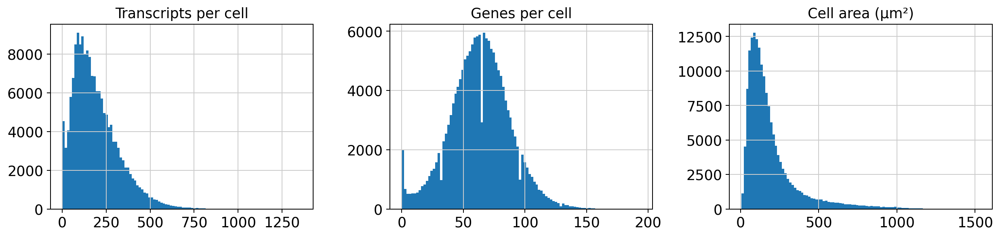

       total_counts  n_genes_by_counts  cell_area
count      167780.0           167780.0   167780.0
mean          191.3               63.2      193.7
std           129.4               24.6      174.4
min             0.0                0.0        5.2
25%            96.0               48.0       86.0
50%           164.0               64.0      140.3
75%           262.0               79.0      229.5
max          1359.0              194.0     1532.7


In [5]:
sc.pp.calculate_qc_metrics(adata, percent_top=None, inplace=True)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
axs[0].hist(adata.obs["total_counts"], bins=100); axs[0].set_title("Transcripts per cell")
axs[1].hist(adata.obs["n_genes_by_counts"], bins=100); axs[1].set_title("Genes per cell")
axs[2].hist(adata.obs["cell_area"], bins=100); axs[2].set_title("Cell area (µm²)")
plt.tight_layout(); plt.savefig(FIG_DIR / "qc_histograms.png"); plt.show()

print(adata.obs[["total_counts", "n_genes_by_counts", "cell_area"]].describe().round(1))

In [7]:
n_before = adata.n_obs
sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=5)
print(f"kept {adata.n_obs:,} of {n_before:,} cells, {adata.n_vars} genes")

kept 165,423 of 167,780 cells, 313 genes


## 5. Normalization, PCA, UMAP, clustering

Xenium panels are small (313 genes), so we keep all genes instead of selecting highly variable ones.

In [8]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

sc.pp.pca(adata, n_comps=30, random_state=RANDOM_STATE)
sc.pp.neighbors(adata, n_neighbors=15, random_state=RANDOM_STATE)
sc.tl.umap(adata, random_state=RANDOM_STATE)
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2,
             directed=False, random_state=RANDOM_STATE)
print(adata.obs["leiden"].value_counts().sort_index())

leiden
0    16452
1    14240
2    16338
3    20179
4    36419
5    30771
6     8939
7     4289
8    12632
9     5164
Name: count, dtype: int64


/tmp/ipykernel_1264/2289193095.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata, color="leiden", legend_loc="on data", save="_leiden.png")


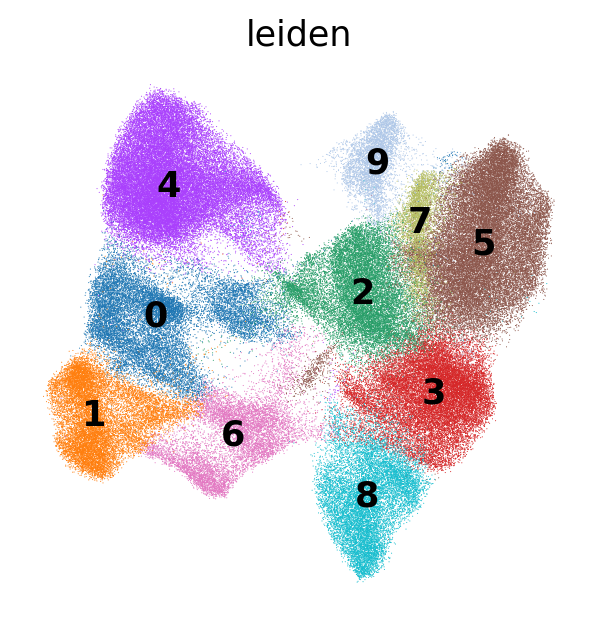

,0,1,2,3,4,5,6,7,8,9
0,ERBB2,CEACAM6,FCER1G,LUM,FASN,CD3E,KRT14,MS4A1,CAV1,ITM2C
1,KRT8,GATA3,LYZ,POSTN,EPCAM,TRAC,KRT5,BANK1,CD93,TENT5C
2,TACSTD2,TACSTD2,FGL2,CCDC80,FOXA1,PTPRC,SFRP1,CXCR4,PECAM1,SLAMF7
3,S100A14,CD9,CD4,MMP2,KRT7,IL7R,KRT15,SELL,AQP1,MZB1
4,CEACAM6,MLPH,CD68,PDGFRB,ABCC11,CXCR4,KRT6B,PTPRC,VWF,SEC11C
5,CCND1,TPD52,AIF1,PDGFRA,MLPH,CYTIP,PTN,SMAP2,CLEC14A,PRDM1
6,KRT7,KRT8,CD163,FBLN1,ANKRD30A,IL2RG,SERPINA3,GPR183,RAMP2,ERN1
7,CDH1,ANKRD30A,PDK4,CXCL12,GATA3,S100A4,DST,IL2RG,KDR,TPD52


In [9]:
sc.pl.umap(adata, color="leiden", legend_loc="on data", save="_leiden.png")
sc.tl.rank_genes_groups(adata, "leiden", method="wilcoxon")
pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(8)

## 6. Cell type annotation

Score each cluster against known marker genes, then assign the best-matching type. **Check the result against the top marker table above and adjust by hand** where it looks wrong. That manual check is part of the work and worth mentioning in an interview.

In [10]:
MARKERS = {
    "Tumor/Epithelial": ["EPCAM", "KRT7", "KRT8", "ERBB2", "CEACAM6", "FOXA1", "GATA3", "ESR1"],
    "Myoepithelial":    ["KRT5", "KRT14", "ACTA2", "MYLK", "OXTR"],
    "T cells":          ["CD3E", "CD3D", "CD8A", "CD4", "IL7R", "TRAC", "CD247"],
    "B cells":          ["MS4A1", "CD79A", "BANK1", "CD19"],
    "Plasma cells":     ["MZB1", "TNFRSF17", "JCHAIN"],
    "Macrophages":      ["CD68", "CD163", "LYZ", "FCGR3A", "ITGAX", "C1QA"],
    "Dendritic cells":  ["LAMP3", "CLEC9A", "CD1C"],
    "Mast cells":       ["CPA3", "KIT", "TPSAB1"],
    "Endothelial":      ["PECAM1", "VWF", "CD93", "KDR"],
    "Fibroblasts":      ["POSTN", "LUM", "PDGFRA", "MMP2", "COL1A1", "SFRP4"],
    "Adipocytes":       ["ADIPOQ", "LPL", "PLIN1"],
}
present = {k: [g for g in v if g in adata.var_names] for k, v in MARKERS.items()}
present = {k: v for k, v in present.items() if len(v) >= 1}
for k, v in present.items():
    print(f"{k:18s} {v}")

for ct, genes in present.items():
    sc.tl.score_genes(adata, genes, score_name=f"score_{ct}", random_state=RANDOM_STATE)

score_cols = [f"score_{ct}" for ct in present]
cluster_scores = adata.obs.groupby("leiden", observed=True)[score_cols].mean()
cluster_scores.columns = list(present)
cluster_to_type = cluster_scores.idxmax(axis=1).to_dict()

# Manual corrections go here after you inspect the marker table, e.g.:
# cluster_to_type["7"] = "Dendritic cells"

adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_to_type).astype("category")
print(adata.obs["cell_type"].value_counts())

Tumor/Epithelial   ['EPCAM', 'KRT7', 'KRT8', 'ERBB2', 'CEACAM6', 'FOXA1', 'GATA3', 'ESR1']
Myoepithelial      ['KRT5', 'KRT14', 'ACTA2', 'MYLK', 'OXTR']
T cells            ['CD3E', 'CD3D', 'CD8A', 'CD4', 'IL7R', 'TRAC', 'CD247']
B cells            ['MS4A1', 'CD79A', 'BANK1', 'CD19']
Plasma cells       ['MZB1', 'TNFRSF17']
Macrophages        ['CD68', 'CD163', 'LYZ', 'FCGR3A', 'ITGAX', 'C1QA']
Dendritic cells    ['CLEC9A', 'CD1C']
Mast cells         ['CPA3', 'KIT', 'TPSAB1']
Endothelial        ['PECAM1', 'VWF', 'CD93', 'KDR']
Fibroblasts        ['POSTN', 'LUM', 'PDGFRA', 'MMP2', 'SFRP4']
Adipocytes         ['ADIPOQ', 'LPL']
cell_type
Tumor/Epithelial    67111
T cells             30771
Fibroblasts         20179
Macrophages         16338
Endothelial         12632
Myoepithelial        8939
Plasma cells         5164
B cells              4289
Name: count, dtype: int64


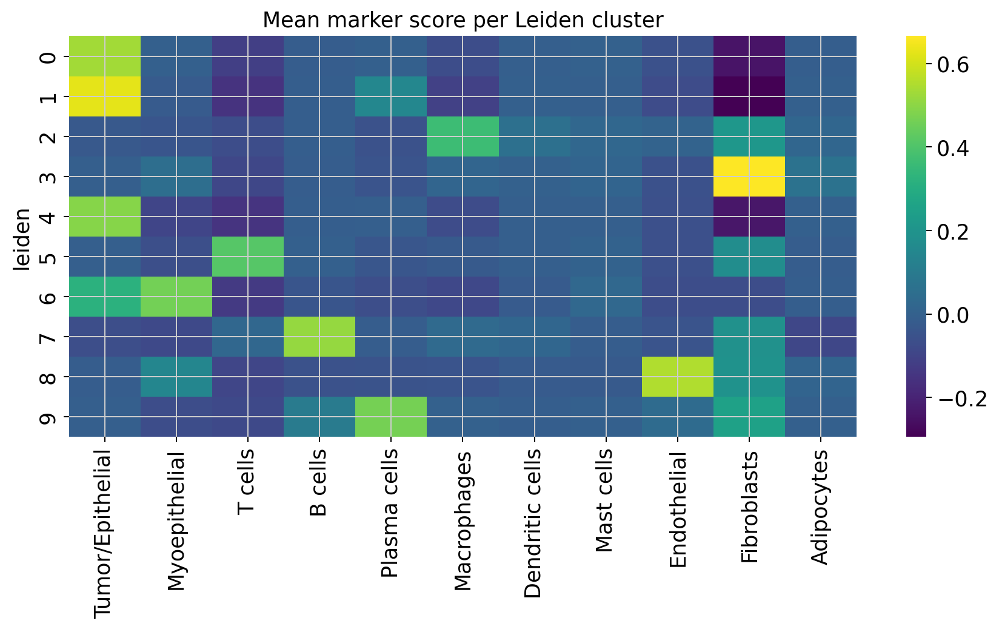

/tmp/ipykernel_1264/2199058675.py:7: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata, color="cell_type", save="_cell_type.png")


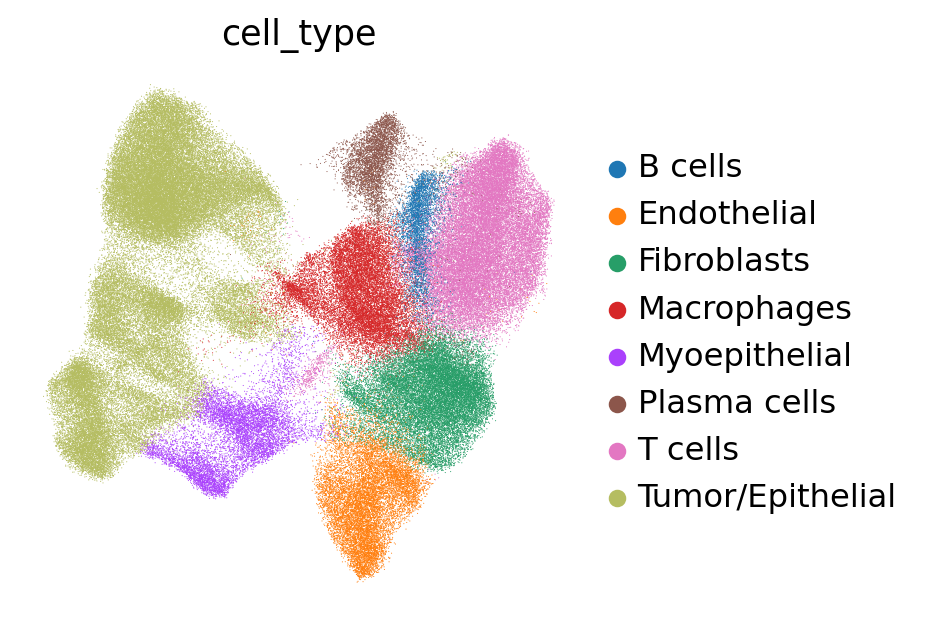

/tmp/ipykernel_1264/2199058675.py:8: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(adata, present, groupby="cell_type", standard_scale="var", save="_markers.png")


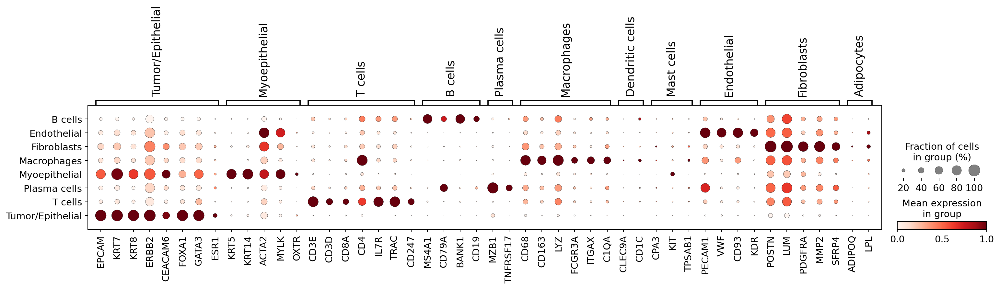

In [11]:
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.heatmap(cluster_scores, cmap="viridis")
plt.title("Mean marker score per Leiden cluster"); plt.tight_layout()
plt.savefig(FIG_DIR / "annotation_scores.png"); plt.show()

sc.pl.umap(adata, color="cell_type", save="_cell_type.png")
sc.pl.dotplot(adata, present, groupby="cell_type", standard_scale="var", save="_markers.png")

## 7. Spatial maps

/tmp/ipykernel_1264/4038775274.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.embedding(adata, basis="spatial", color="cell_type", s=1, save="_spatial_cell_type.png")


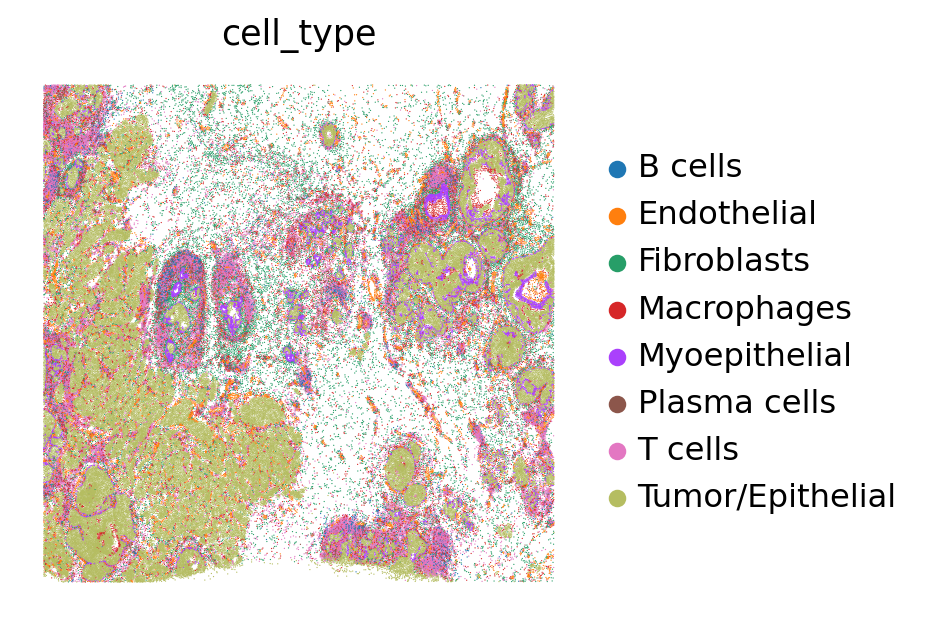

/tmp/ipykernel_1264/4038775274.py:3: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.embedding(adata, basis="spatial", color=g, s=1, cmap="magma", save=f"_spatial_{g}.png")


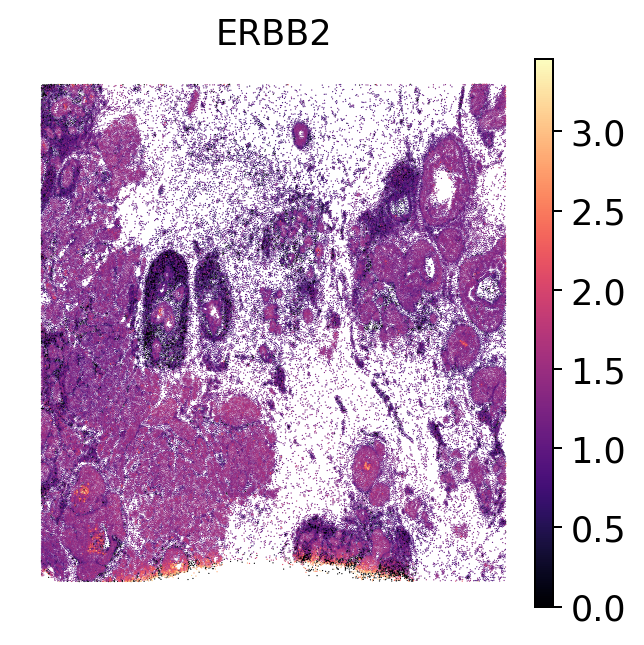

/tmp/ipykernel_1264/4038775274.py:3: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.embedding(adata, basis="spatial", color=g, s=1, cmap="magma", save=f"_spatial_{g}.png")


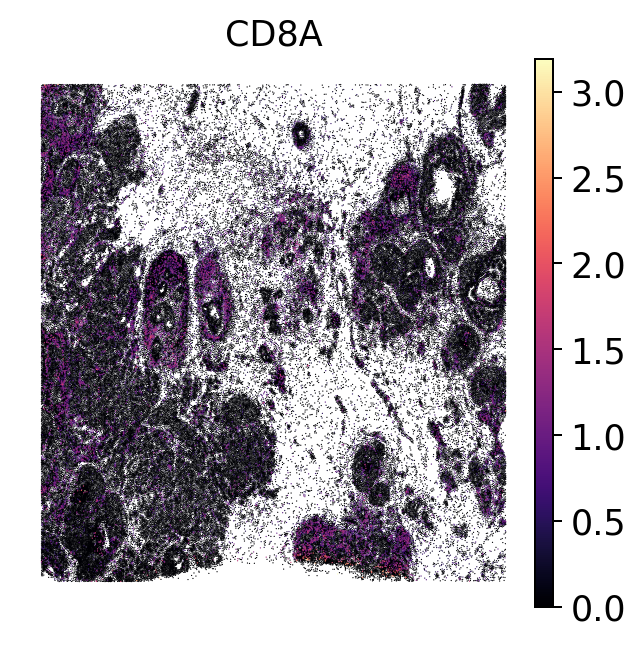

/tmp/ipykernel_1264/4038775274.py:3: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.embedding(adata, basis="spatial", color=g, s=1, cmap="magma", save=f"_spatial_{g}.png")


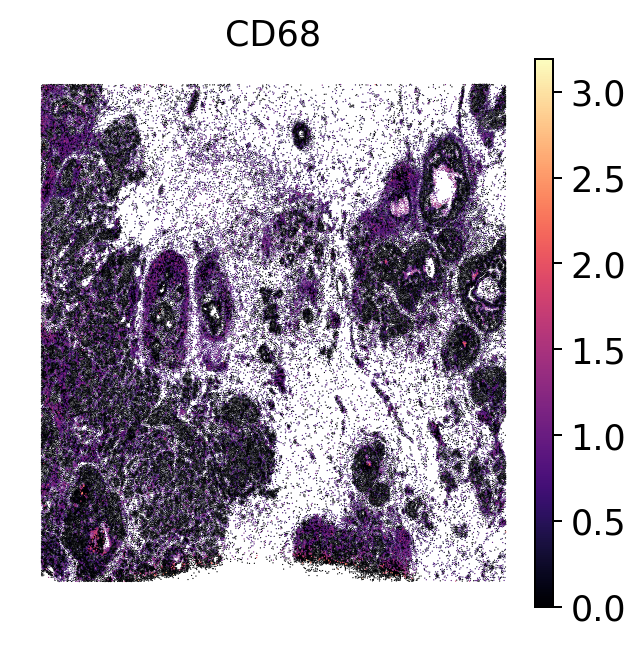

/tmp/ipykernel_1264/4038775274.py:3: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.embedding(adata, basis="spatial", color=g, s=1, cmap="magma", save=f"_spatial_{g}.png")


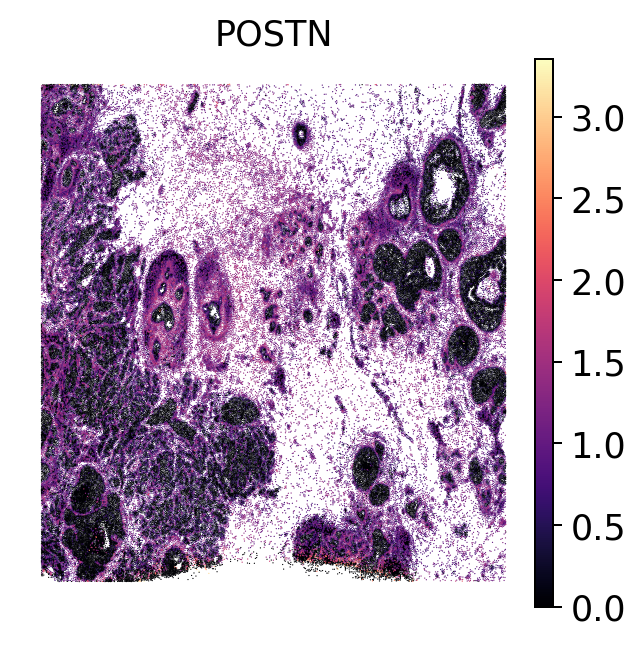

In [12]:
sc.pl.embedding(adata, basis="spatial", color="cell_type", s=1, save="_spatial_cell_type.png")
for g in [g for g in ["ERBB2", "CD8A", "CD68", "POSTN"] if g in adata.var_names]:
    sc.pl.embedding(adata, basis="spatial", color=g, s=1, cmap="magma", save=f"_spatial_{g}.png")

## 8. Spatial neighborhood enrichment

Build a k-nearest-neighbor graph on the cell centroids, then test whether two cell types are neighbors more (or less) often than expected by chance, using a permutation test. Positive z-score = enriched contact, negative = avoidance.

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_1264/1094370669.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, coord_type="generic", n_neighs=10)
/tmp/ipykernel_1264/1094370669.py:2: FutureWarning: Parameter `seed` of `nhood_enrichment()` is deprecated in favor of `rng` and will be removed in squidpy v1.9.0. It is now seeding a generator, i.e. `seed=42` is used as `numpy.random.default_rng(42)`, which may change the result.
  sq.gr.nhood_enrichment(adata, cluster_key="cell_type", n_perms=500, seed=RANDOM_STATE)


nhood_enrichment:   0%|          | 0/500 [00:00<?, ?perm/s]

,B cells,Endothelial,Fibroblasts,Macrophages,Myoepithelial,Plasma cells,T cells,Tumor/Epithelial
B cells,125.2,-18.4,-11.6,31.5,-48.3,27.7,149.0,-173.2
Endothelial,-20.9,271.6,13.1,15.7,-35.0,-7.9,1.6,-183.5
Fibroblasts,-4.4,42.9,248.9,83.9,-31.1,52.0,-4.4,-287.7
Macrophages,33.6,27.9,75.3,105.5,-42.4,48.3,92.3,-217.8
Myoepithelial,-48.6,-43.1,-47.8,-53.7,394.2,-48.6,-102.8,-44.1
Plasma cells,29.9,-0.3,47.5,50.9,-44.8,138.3,65.8,-164.8
T cells,147.9,8.1,-19.6,86.4,-96.1,57.8,302.5,-392.3
Tumor/Epithelial,-149.4,-176.3,-268.2,-215.8,-42.1,-148.0,-357.6,612.4


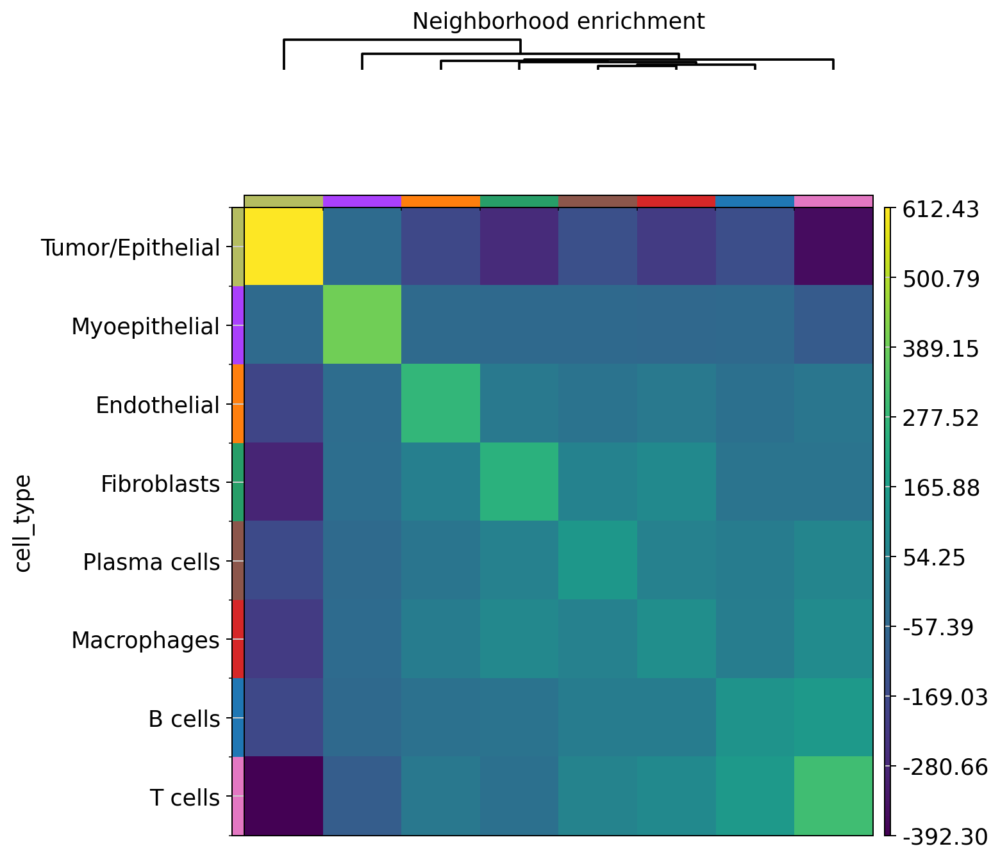

In [13]:
sq.gr.spatial_neighbors(adata, coord_type="generic", n_neighs=10)
sq.gr.nhood_enrichment(adata, cluster_key="cell_type", n_perms=500, seed=RANDOM_STATE)
sq.pl.nhood_enrichment(adata, cluster_key="cell_type", method="average",
                       figsize=(7, 7), save="nhood_enrichment.png")

z = pd.DataFrame(adata.uns["cell_type_nhood_enrichment"]["zscore"],
                 index=adata.obs["cell_type"].cat.categories,
                 columns=adata.obs["cell_type"].cat.categories)
z.round(1)

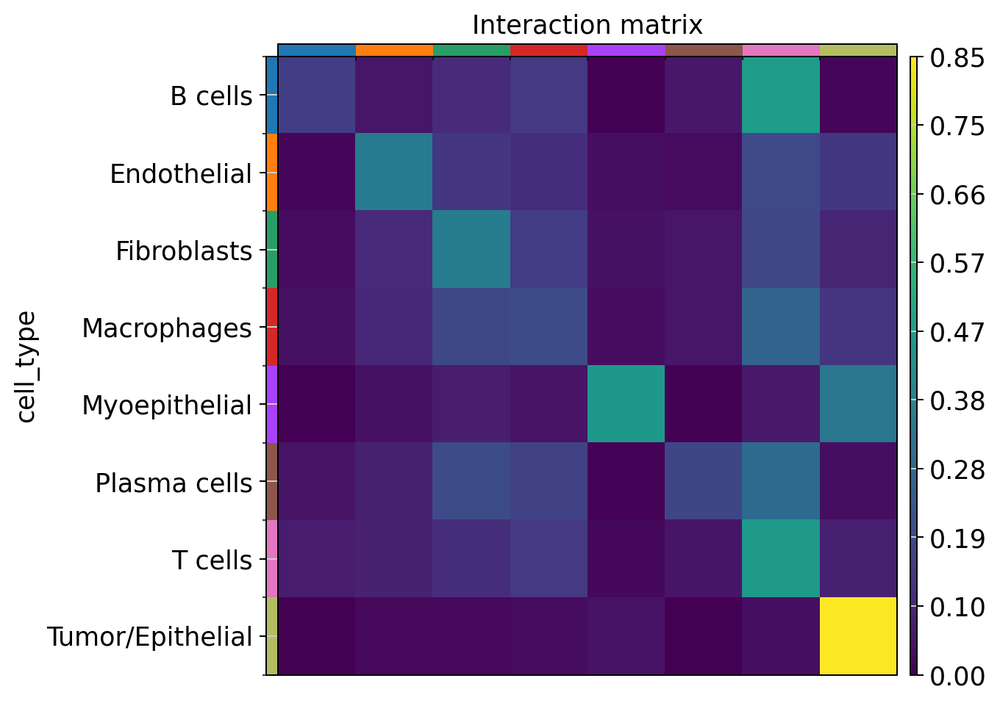

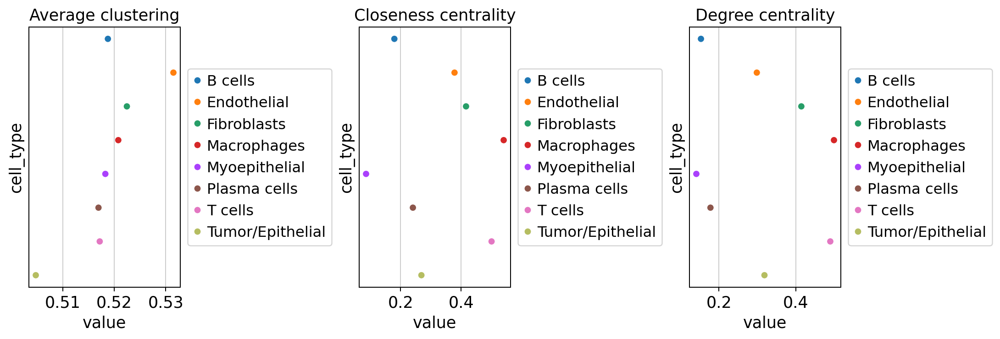

In [14]:
sq.gr.interaction_matrix(adata, cluster_key="cell_type", normalized=True)
sq.pl.interaction_matrix(adata, cluster_key="cell_type", save="interaction_matrix.png")
sq.gr.centrality_scores(adata, cluster_key="cell_type")
sq.pl.centrality_scores(adata, cluster_key="cell_type", figsize=(12, 4), save="centrality.png")

## 9. Co-occurrence across distance

How likely is cell type B to be found at distance *d* from a tumor cell, relative to chance? Computed on a central 2 × 2 mm window to keep it fast.

window: 18,762 cells


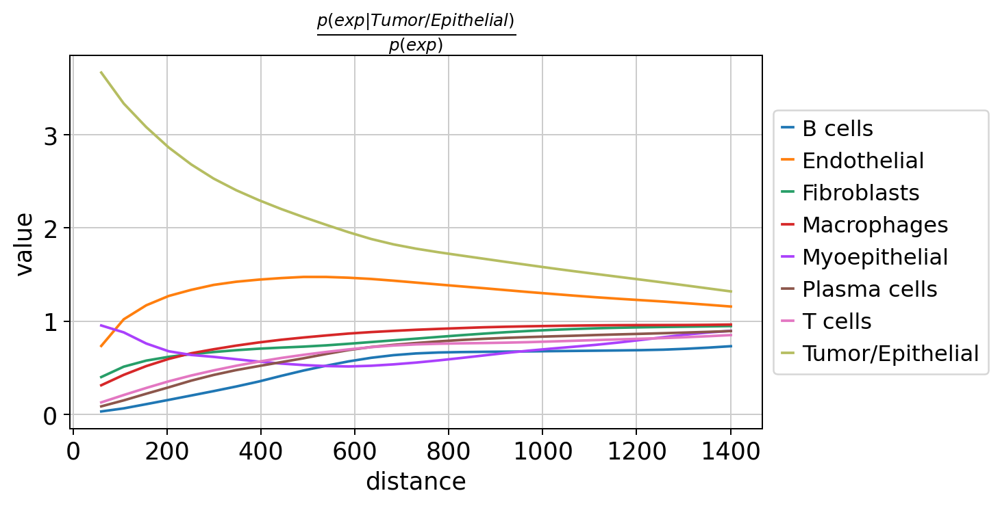

In [15]:
xy = adata.obsm["spatial"]
cx, cy = np.median(xy, axis=0)
win = (np.abs(xy[:, 0] - cx) < 1000) & (np.abs(xy[:, 1] - cy) < 1000)
ad_win = adata[win].copy()
print(f"window: {ad_win.n_obs:,} cells")

sq.gr.co_occurrence(ad_win, cluster_key="cell_type", interval=30)
sq.pl.co_occurrence(ad_win, cluster_key="cell_type", clusters=["Tumor/Epithelial"],
                    figsize=(8, 4), save="co_occurrence_tumor.png")

## 10. Spatially variable genes (Moran's I)

Genes with high Moran's I form spatial patterns (clustered in particular regions) rather than being scattered randomly.

,I,pval_norm,var_norm,pval_norm_fdr_bh
KRT7,0.673990,0.0,0.000001,0.0
EPCAM,0.649407,0.0,0.000001,0.0
FASN,0.641348,0.0,0.000001,0.0
FOXA1,0.634741,0.0,0.000001,0.0
SCD,0.627161,0.0,0.000001,0.0
KRT8,0.609071,0.0,0.000001,0.0
TACSTD2,0.608029,0.0,0.000001,0.0
CEACAM6,0.583301,0.0,0.000001,0.0
MLPH,0.558198,0.0,0.000001,0.0
GATA3,0.551756,0.0,0.000001,0.0


/tmp/ipykernel_1264/1846322220.py:4: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.embedding(adata, basis="spatial", color=moran.index[:4].tolist(), s=1, cmap="magma",


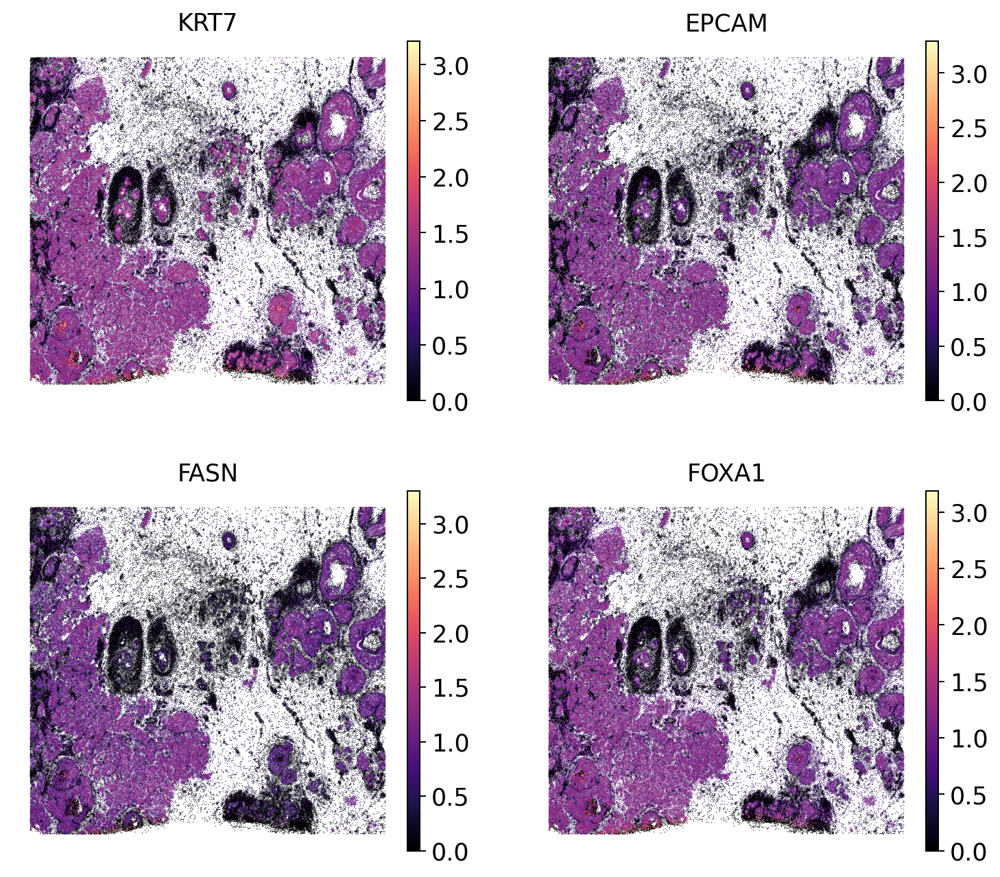

In [16]:
sq.gr.spatial_autocorr(adata, mode="moran", genes=adata.var_names.tolist(), n_perms=None, n_jobs=2)
moran = adata.uns["moranI"].sort_values("I", ascending=False)
display(moran.head(15))
sc.pl.embedding(adata, basis="spatial", color=moran.index[:4].tolist(), s=1, cmap="magma",
                ncols=2, save="_top_svgs.png")

## 11. Niche detection

For every cell, count the cell types among its spatial neighbors and turn that into a composition vector. Cluster these vectors with k-means. Each cluster is a **niche**, a recurring local microenvironment (e.g. "tumor core", "immune-infiltrated tumor border", "stroma").

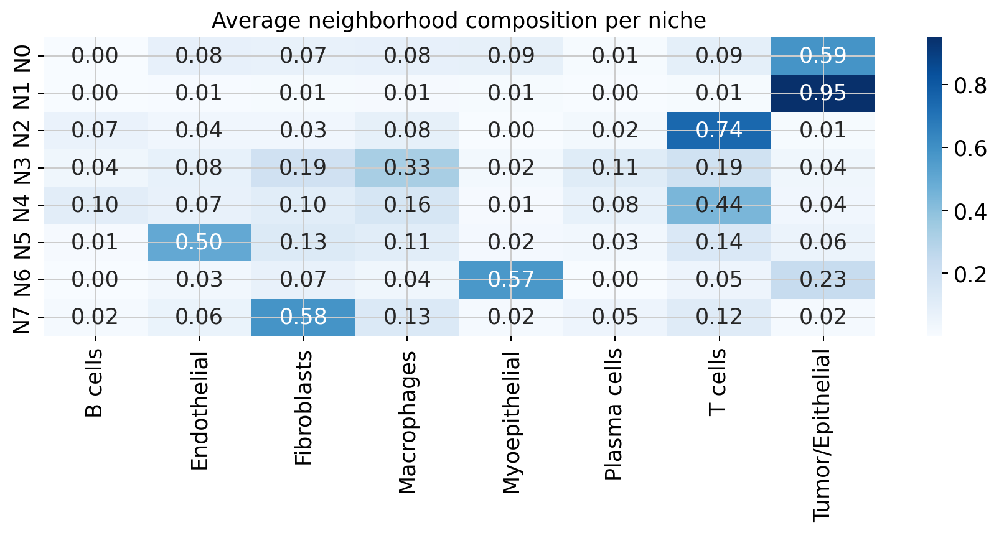

/tmp/ipykernel_1264/2010914198.py:19: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.embedding(adata, basis="spatial", color="niche", s=1, save="_spatial_niches.png")


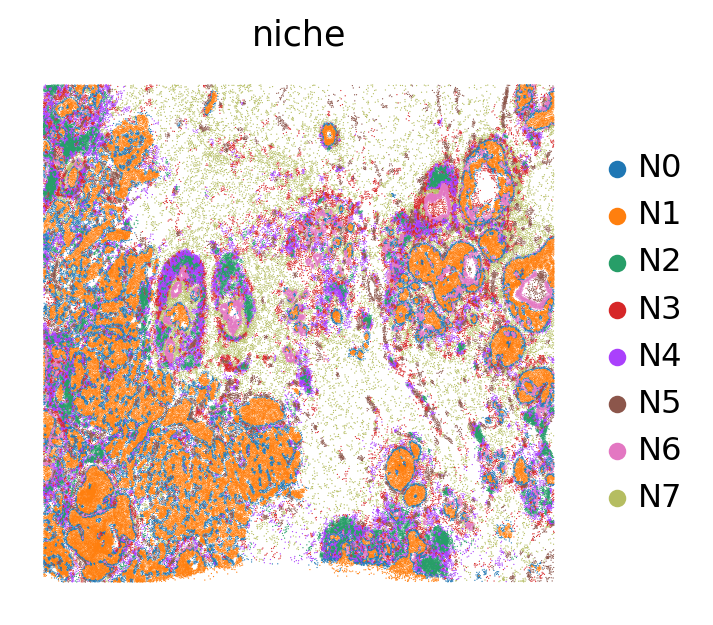

In [18]:
conn = adata.obsp["spatial_connectivities"].tocsr()
conn = ((conn + sp.identity(conn.shape[0], format="csr")) > 0).astype(float)  # include the cell itself

onehot = pd.get_dummies(adata.obs["cell_type"]).astype(float)
comp = conn @ onehot.to_numpy()
comp = comp / comp.sum(axis=1, keepdims=True)
comp_df = pd.DataFrame(comp, index=adata.obs_names, columns=onehot.columns)

N_NICHES = 8
km = KMeans(n_clusters=N_NICHES, n_init=10, random_state=RANDOM_STATE).fit(comp)
adata.obs["niche"] = pd.Categorical("N" + pd.Series(km.labels_).astype(str).values)

niche_profile = comp_df.groupby(adata.obs["niche"].values).mean()
plt.figure(figsize=(10, 5))
sns.heatmap(niche_profile, cmap="Blues", annot=True, fmt=".2f")
plt.title("Average neighborhood composition per niche"); plt.tight_layout()
plt.savefig(FIG_DIR / "niche_composition.png"); plt.show()

sc.pl.embedding(adata, basis="spatial", color="niche", s=1, save="_spatial_niches.png")

Give the niches readable names based on the heatmap, e.g.:

In [ ]:
NICHE_NAMES = {
    "N0": "Tumor border", "N1": "Tumor core", "N2": "T-cell zone", "N3": "Myeloid-rich immune stroma",
    "N4": "Lymphoid aggregate", "N5": "Vascular niche", "N6": "Duct wall (DCIS-like)", "N7": "Fibroblast stroma",
}
adata.obs["niche_name"] = adata.obs["niche"].map(NICHE_NAMES).astype("category")
sc.pl.embedding(adata, basis="spatial", color="niche_name", s=1)

## 12. Contrast: tumor cells in immune-rich vs immune-poor neighborhoods

This mirrors the Charité question of how tumor states relate to immune neighbors. For each tumor cell, take the immune fraction of its neighborhood. Compare the top and bottom quartile with a Wilcoxon test (Benjamini–Hochberg corrected).

In [20]:
IMMUNE = [c for c in ["T cells", "B cells", "Plasma cells", "Macrophages", "Dendritic cells", "Mast cells"]
          if c in comp_df.columns]
adata.obs["immune_frac"] = comp_df[IMMUNE].sum(axis=1).values

tumor = adata[adata.obs["cell_type"] == "Tumor/Epithelial"].copy()
lo, hi = tumor.obs["immune_frac"].quantile([0.25, 0.75])
tumor.obs["immune_context"] = np.select(
    [tumor.obs["immune_frac"] >= hi, tumor.obs["immune_frac"] <= lo],
    ["immune_rich", "immune_poor"], default="middle")
tumor = tumor[tumor.obs["immune_context"] != "middle"].copy()
print(tumor.obs["immune_context"].value_counts())

sc.tl.rank_genes_groups(tumor, "immune_context", groups=["immune_rich"], reference="immune_poor",
                        method="wilcoxon")
de = sc.get.rank_genes_groups_df(tumor, group="immune_rich")
de_sig = de[(de["pvals_adj"] < 0.05) & (de["logfoldchanges"].abs() > 0.5)]
display(de_sig.head(20))
de.to_csv("results/de_tumor_immune_rich_vs_poor.csv", index=False)

immune_context
immune_poor    44687
immune_rich    22424
Name: count, dtype: int64


,names,scores,logfoldchanges,pvals,pvals_adj
0,POSTN,45.185215,1.271253,0.000000e+00,0.000000e+00
1,LUM,43.140636,1.088535,0.000000e+00,0.000000e+00
2,FCER1G,31.748016,1.522487,3.381908e-221,2.117074e-219
4,LYZ,27.592028,1.386707,1.386918e-167,3.946413e-166
5,CD68,26.983927,1.516474,2.281981e-160,5.101859e-159
6,AIF1,23.024685,1.616163,2.638328e-117,4.346299e-116
7,ZEB2,22.665091,1.395101,9.904567e-114,1.476252e-112
8,APOC1,22.064657,1.645643,6.908987e-108,9.402230e-107
9,CXCR4,20.964266,0.521697,1.390489e-97,1.740892e-96
10,CXCL12,20.742714,1.175883,1.426475e-95,1.717256e-94


In [ ]:
# Volcano plot
de["neglog10"] = -np.log10(de["pvals_adj"].clip(lower=1e-300))
plt.figure(figsize=(6, 5))
plt.scatter(de["logfoldchanges"], de["neglog10"], s=8, c="grey")
plt.scatter(de_sig["logfoldchanges"], -np.log10(de_sig["pvals_adj"].clip(lower=1e-300)), s=10, c="crimson")
for _, r in de_sig.nlargest(10, "scores").iterrows():
    plt.annotate(r["names"], (r["logfoldchanges"], -np.log10(max(r["pvals_adj"], 1e-300))), fontsize=8)
plt.axvline(0, c="k", lw=0.5); plt.xlabel("log2 fold change (immune-rich vs poor)"); plt.ylabel("-log10 adj. p")
plt.title("Tumor cells: immune-rich vs immune-poor neighborhoods"); plt.tight_layout()
plt.savefig(FIG_DIR / "volcano_tumor_immune_context.png"); plt.show()

**Caveat to write down:** with imaging-based data, transcripts from neighboring cells can leak into a cell's segmentation mask. Some "upregulated" genes in immune-rich tumor cells may be immune genes (e.g. *PTPRC*, *CD3E*) picked up from neighbors. Flag these instead of reporting them as tumor biology. Noticing this is exactly the kind of critical thinking a PhD supervisor looks for.

## 13. Ligand–receptor analysis

A permutation test on ligand–receptor pairs (OmniPath database) between cell types. With a 313-gene panel only some pairs are covered, so treat this as hypothesis-generating. Run on a 30k-cell subsample for speed.

/tmp/ipykernel_1264/4231296846.py:3: FutureWarning: Parameter `seed` of `ligrec()` is deprecated in favor of `rng` and will be removed in squidpy v1.9.0. It is now seeding a generator, i.e. `seed=42` is used as `numpy.random.default_rng(42)`, which may change the result.
  lr = sq.gr.ligrec(sub, cluster_key="cell_type", use_raw=False, n_perms=200,


0.00B [00:00, ?B/s]

0.00B [00:00, ?B/s]

0.00B [00:00, ?B/s]

  0%|          | 0/200 [00:00<?, ?permutation/s]

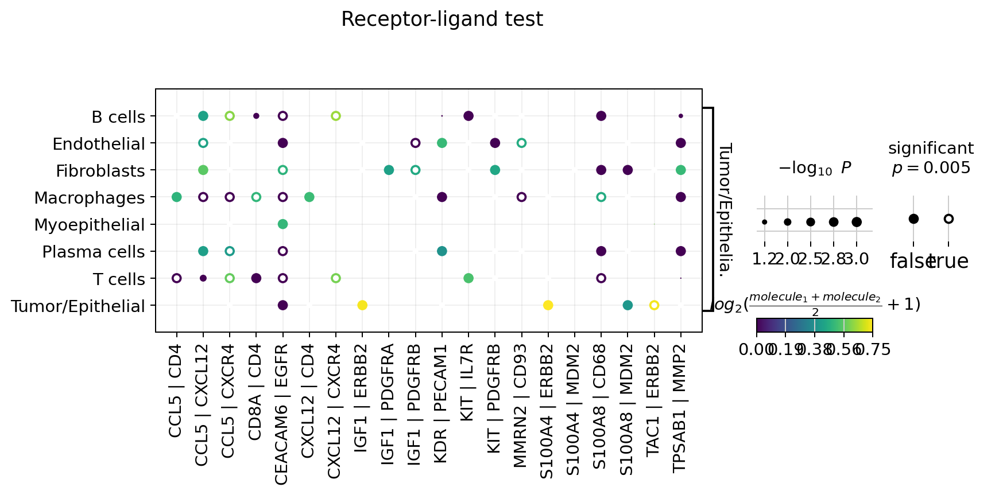

In [21]:
sub = sc.pp.subsample(adata, n_obs=min(30000, adata.n_obs), random_state=RANDOM_STATE, copy=True)
try:
    lr = sq.gr.ligrec(sub, cluster_key="cell_type", use_raw=False, n_perms=200,
                      seed=RANDOM_STATE, copy=True,
                      transmitter_params={"categories": "ligand"},
                      receiver_params={"categories": "receptor"})
    sq.pl.ligrec(lr, source_groups="Tumor/Epithelial", alpha=0.005,
                 means_range=(0.3, np.inf), remove_empty_interactions=True,
                 swap_axes=True, save="ligrec_tumor_source.png")
except Exception as e:
    print("ligrec could not run (needs internet for OmniPath / API differences):", e)

In [23]:
# Replace "/" in column and key names so the .h5ad file can be written
adata.obs.columns = [c.replace("/", "_") for c in adata.obs.columns]
adata.var.columns = [c.replace("/", "_") for c in adata.var.columns]

def clean_keys(d):
    if isinstance(d, dict):
        return {str(k).replace("/", "_"): clean_keys(v) for k, v in d.items()}
    return d
adata.uns = clean_keys(adata.uns)

adata.write_h5ad("results/xenium_breast_rep1_annotated.h5ad", compression="gzip")
print("saved")

saved


## 14. Save results

In [24]:
niche_counts = pd.crosstab(adata.obs["niche"], adata.obs["cell_type"])
niche_counts.to_csv("results/niche_by_cell_type_counts.csv")
moran.to_csv("results/moran_spatially_variable_genes.csv")
z.to_csv("results/nhood_enrichment_zscores.csv")
adata.write_h5ad("results/xenium_breast_rep1_annotated.h5ad", compression="gzip")
print("saved:", sorted(p.name for p in Path("results").rglob("*") if p.is_file()))

saved: ['annotation_scores.png', 'centrality.png', 'co_occurrence_tumor.png', 'de_tumor_immune_rich_vs_poor.csv', 'dotplot__markers.png', 'interaction_matrix.png', 'ligrec_tumor_source.png', 'moran_spatially_variable_genes.csv', 'nhood_enrichment.png', 'nhood_enrichment_zscores.csv', 'niche_by_cell_type_counts.csv', 'niche_composition.png', 'qc_histograms.png', 'spatial_spatial_CD68.png', 'spatial_spatial_CD8A.png', 'spatial_spatial_ERBB2.png', 'spatial_spatial_POSTN.png', 'spatial_spatial_cell_type.png', 'spatial_spatial_niches.png', 'spatial_top_svgs.png', 'umap_cell_type.png', 'umap_leiden.png', 'xenium_breast_rep1_annotated.h5ad']


## 15. Summary

**Data:** 165,423 cells after QC (of 167,780), 313 genes, median 164 transcripts and 64 genes per cell.

**Cell types (10 Leiden clusters → 8 types):** Tumor/Epithelial 67,111 (41%) · T cells 30,771 (19%) · Fibroblasts 20,179 (12%) · Macrophages 16,338 (10%) · Endothelial 12,632 (8%) · Myoepithelial 8,939 (5%) · Plasma cells 5,164 (3%) · B cells 4,289 (3%). Three clusters are tumor (ERBB2/KRT8, CEACAM6/GATA3, FASN/FOXA1). All cluster labels agreed with the top marker genes, so no manual correction was needed.

**Spatial contacts (neighborhood enrichment z-scores, both directions averaged):**
- Every cell type is most enriched with itself (tumor 612, myoepithelial 394, T cells 303). The tissue is organized into compartments, not mixed.
- Strongest cross-type contacts: T cells–B cells (~148), T cells–macrophages (~89), macrophages–fibroblasts (~80), plasma cells–macrophages and plasma–fibroblasts (~50).
- Strongest avoidance: tumor–T cells (~ –375), tumor–fibroblasts (~ –278), tumor–macrophages (~ –217), tumor–endothelial (~ –180).
- Myoepithelial cells avoid almost everything, but avoid tumor the least (~ –43). They line the ducts around tumor cells, which fits ductal carcinoma in situ (DCIS) regions.

**Tumor–immune pattern:** this section looks like an immune-excluded ("cold") tumor. Tumor cells form dense nests (co-occurrence ratio ~3.7 at short distance). T cells, B cells and plasma cells are nearly absent within ~100 µm of tumor cells (ratio < 0.2) and only approach background levels beyond ~800 µm. Immune cells collect in the stroma, in T/B-rich aggregates and macrophage-rich regions, rather than inside the tumor nests. Endothelial cells peak at 200–600 µm from tumor cells, which suggests vessels run through the stroma around the nests.

**Niches (k = 8, from 10-nearest-neighbor composition):**
| Niche | Main composition | Name |
|---|---|---|
| N1 | 95% tumor | Tumor core |
| N0 | 59% tumor + mixed stroma/immune | Tumor border |
| N6 | 57% myoepithelial + 23% tumor | Duct wall (DCIS-like) |
| N2 | 74% T cells | T-cell zone |
| N4 | 44% T, 16% macrophages, 10% B, 8% plasma | Lymphoid aggregate |
| N3 | 33% macrophages, 19% fibroblasts, 19% T, 11% plasma | Myeloid-rich immune stroma |
| N7 | 58% fibroblasts | Fibroblast stroma |
| N5 | 50% endothelial | Vascular niche |

**Immune-rich vs immune-poor tumor cells (22,424 vs 44,687 cells):**
- The genes "up" in immune-rich tumor cells are almost all macrophage or fibroblast genes: CD68, LYZ, FCER1G, AIF1, C1QC, FCGR3A, CD4 (macrophage) and POSTN, LUM, MMP2, CCDC80 (fibroblast). This is most likely **segmentation spillover**: transcripts from neighboring cells assigned to border tumor cells. It is not tumor biology.
- Possible tumor-intrinsic candidates, to treat as hypotheses only: LDHB and PDK4 (metabolism), ZEB2 and S100A4 (EMT-related, but both are also expressed by immune and stromal cells).
- Note: "immune-poor" is larger than a quartile because many tumor cells have zero immune neighbors. In practice it means "no immune cells among the 10 nearest neighbors".

**Ligand–receptor (tumor as sender, hypothesis-generating):** significant pairs include CEACAM6–EGFR (tumor → several cell types), IGF1–PDGFRB (→ endothelial and fibroblasts), MMRN2–CD93 (→ endothelial) and S100A8–CD68 (→ macrophages). Ligands such as CCL5 and CXCL12 are normally made by T cells and fibroblasts, so their signal from "tumor" cells is probably spillover too.

**Spatially variable genes (Moran's I):** epithelial genes are the most spatially structured (KRT7 0.67, EPCAM 0.65, FASN 0.64, FOXA1 0.63, SCD, KRT8, GATA3), followed by stromal genes (LUM, POSTN, CXCL12, CCDC80). The strongest spatial signal is the tumor-vs-stroma split.

**Limitations:** one tissue section, no clinical contrast, 313-gene panel, marker-based annotation (no subtypes such as CD8 vs CD4 T cells), and segmentation spillover that dominates the border DE result.

**Next steps:** replicate 2 for reproducibility; spillover-aware analysis (e.g. restrict DE to tumor-specific genes, or re-segment); finer immune subtyping; label transfer from matched scFFPE-seq; add the post-Xenium IF/H&E images; apply the pipeline to pre/post-treatment or primary/metastasis cohorts.
